## Compare results before and after tuning by manually computing and visualizing performance improvements across multiple models, ensuring a thorough analysis of convergence and generalization.

In [1]:

import os
import itertools
import math
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

In [3]:
from sklearn.model_selection import train_test_split, StratifiedKFold
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.base import clone
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

In [17]:
if os.path.exists("/home/patel-krish/anaconda3/BrainyBeam/heart.csv"):
    df = pd.read_csv("/home/patel-krish/anaconda3/BrainyBeam/heart.csv")
elif os.path.exists("/home/patel-krish/anaconda3/BrainyBeam/heart.csv"):
    df = pd.read_csv("/home/patel-krish/anaconda3/BrainyBeam/heart.csv")
else:
    raise FileNotFoundError("Heart dataset not found.")

df.columns = df.columns.str.strip()
df = df.drop_duplicates()
df = df.dropna(subset=["target"])

X = df.drop(columns=["target"]).apply(
    pd.to_numeric, errors="coerce"
)

X = X.replace([np.inf, -np.inf], np.nan)

y = pd.to_numeric(df["target"], errors="coerce")

valid = y.notna()
X = X.loc[valid].reset_index(drop=True)
y = y.loc[valid].astype(int).reset_index(drop=True)

if y.nunique() != 2 or y.value_counts().min() < 5:
    raise ValueError("Binary target with at least 5 samples per class required.")

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))



Training samples: 241
Testing samples: 61


In [18]:
models = {
    "Logistic Regression": Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
        ("model", LogisticRegression(max_iter=2000))
    ]),

    "Decision Tree": Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("model", DecisionTreeClassifier(random_state=42))
    ]),

    "Random Forest": Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("model", RandomForestClassifier(
            random_state=42, n_jobs=-1
        ))
    ]),

    "KNN": Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
        ("model", KNeighborsClassifier())
    ]),

    "SVM": Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
        ("model", SVC())
    ])
}

In [19]:
grids = {
    "Logistic Regression": {
        "model__C": [0.01, 0.1, 1, 10, 100],
        "model__solver": ["liblinear", "lbfgs"],
        "model__class_weight": [None, "balanced"]
    },

    "Decision Tree": {
        "model__max_depth": [2, 3, 5, 8, 12, None],
        "model__criterion": ["gini", "entropy"],
        "model__min_samples_split": [2, 5, 10],
        "model__min_samples_leaf": [1, 2, 4]
    },

    "Random Forest": {
        "model__n_estimators": [50, 100, 150, 200],
        "model__max_depth": [3, 5, 8, None],
        "model__min_samples_split": [2, 5, 10],
        "model__max_features": ["sqrt", None]
    },

    "KNN": {
        "model__n_neighbors": [3, 5, 7, 9, 11, 15],
        "model__weights": ["uniform", "distance"],
        "model__p": [1, 2]
    },

    "SVM": {
        "model__C": [0.01, 0.1, 1, 10, 100],
        "model__kernel": ["linear", "rbf"],
        "model__gamma": ["scale", "auto"]
    }
}

In [20]:
def rbf_kernel(A, B, length_scale=0.30):
    diff = A[:, None, :] - B[None, :, :]
    distance = np.sum(diff ** 2, axis=2)

    return np.exp(
        -distance / (2 * length_scale ** 2)
    )


def gp_predict(X_observed, y_observed, X_candidates):
    K = rbf_kernel(X_observed, X_observed)
    K += np.eye(len(X_observed)) * 1e-6

    K_star = rbf_kernel(X_observed, X_candidates)
    K_candidate = rbf_kernel(X_candidates, X_candidates)

    alpha = np.linalg.solve(K, y_observed)

    mean = K_star.T @ alpha

    solved = np.linalg.solve(K, K_star)

    variance = np.diag(K_candidate) - np.sum(
        K_star * solved, axis=0
    )

    std = np.sqrt(np.maximum(variance, 1e-12))

    return mean, std


def normal_pdf(z):
    return np.exp(-0.5 * z ** 2) / np.sqrt(2 * np.pi)


def normal_cdf(z):
    return np.array([
        0.5 * (1 + math.erf(float(v) / np.sqrt(2)))
        for v in np.asarray(z).ravel()
    ]).reshape(np.asarray(z).shape)


def expected_improvement(mean, std, best_score):
    improvement = mean - best_score - 0.01
    z = improvement / np.maximum(std, 1e-12)

    result = (
        improvement * normal_cdf(z)
        + std * normal_pdf(z)
    )

    return np.maximum(result, 0)


def encode_params(params, grid):
    values = []

    for key, choices in grid.items():
        index = choices.index(params[key])

        if len(choices) == 1:
            values.append(0.0)
        else:
            values.append(index / (len(choices) - 1))

    return values

In [21]:
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)


def evaluate_model(model, params=None):
    scores = []

    for train_idx, valid_idx in cv.split(X_train, y_train):
        X_fold_train = X_train.iloc[train_idx]
        X_fold_valid = X_train.iloc[valid_idx]

        y_fold_train = y_train.iloc[train_idx]
        y_fold_valid = y_train.iloc[valid_idx]

        current_model = clone(model)

        if params is not None:
            current_model.set_params(**params)

        current_model.fit(X_fold_train, y_fold_train)

        prediction = current_model.predict(X_fold_valid)

        scores.append(
            f1_score(
                y_fold_valid,
                prediction,
                zero_division=0
            )
        )

    return float(np.mean(scores))

In [22]:
N_INITIAL = 3
N_ITERATIONS = 10

rng = np.random.default_rng(42)

comparison_results = []
convergence_results = []

best_before_score = -1
best_before_name = None

best_after_score = -1
best_after_name = None
best_after_model = None
best_after_params = None

for model_name, base_model in models.items():

    print("\nOptimizing:", model_name)

    baseline_cv = evaluate_model(base_model)

    baseline_model = clone(base_model)
    baseline_model.fit(X_train, y_train)

    baseline_predictions = baseline_model.predict(X_test)

    baseline_metrics = {
        "Accuracy": accuracy_score(y_test, baseline_predictions),
        "Precision": precision_score(
            y_test, baseline_predictions, zero_division=0
        ),
        "Recall": recall_score(
            y_test, baseline_predictions, zero_division=0
        ),
        "F1": f1_score(
            y_test, baseline_predictions, zero_division=0
        )
    }

    if baseline_metrics["F1"] > best_before_score:
        best_before_score = baseline_metrics["F1"]
        best_before_name = model_name

    grid = grids[model_name]
    keys = list(grid.keys())

    combinations = [
        dict(zip(keys, values))
        for values in itertools.product(
            *[grid[key] for key in keys]
        )
    ]

    candidate_vectors = np.array([
        encode_params(params, grid)
        for params in combinations
    ])

    initial_count = min(N_INITIAL, len(combinations))

    initial_indices = list(
        rng.choice(
            len(combinations),
            size=initial_count,
            replace=False
        )
    )

    observed_X = []
    observed_y = []
    evaluated = set()
    evaluated_params = []

    best_cv = -1
    best_params = None

    for iteration in range(
        min(N_ITERATIONS, len(combinations))
    ):

        if iteration < initial_count:
            next_index = initial_indices[iteration]

        else:
            remaining = [
                i for i in range(len(combinations))
                if i not in evaluated
            ]

            if not remaining:
                break

            mean, std = gp_predict(
                np.array(observed_X),
                np.array(observed_y),
                candidate_vectors[remaining]
            )

            ei = expected_improvement(
                mean, std, max(observed_y)
            )

            next_index = remaining[int(np.argmax(ei))]

        evaluated.add(next_index)

        params = combinations[next_index]

        score = evaluate_model(base_model, params)

        observed_X.append(candidate_vectors[next_index])
        observed_y.append(score)
        evaluated_params.append(params.copy())

        if score > best_cv:
            best_cv = score
            best_params = params.copy()

        convergence_results.append({
            "Model": model_name,
            "Iteration": iteration + 1,
            "CV_F1": score,
            "Best_CV_F1": best_cv
        })

        print(
            f"Iteration {iteration + 1}: "
            f"F1={score:.4f}, Best={best_cv:.4f}"
        )

    tuned_model = clone(base_model)
    tuned_model.set_params(**best_params)
    tuned_model.fit(X_train, y_train)

    tuned_predictions = tuned_model.predict(X_test)

    tuned_metrics = {
        "Accuracy": accuracy_score(y_test, tuned_predictions),
        "Precision": precision_score(
            y_test, tuned_predictions, zero_division=0
        ),
        "Recall": recall_score(
            y_test, tuned_predictions, zero_division=0
        ),
        "F1": f1_score(
            y_test, tuned_predictions, zero_division=0
        )
    }

    comparison_results.append({
        "Model": model_name,
        "Baseline_CV_F1": baseline_cv,
        "Tuned_CV_F1": best_cv,
        "Baseline_Accuracy": baseline_metrics["Accuracy"],
        "Tuned_Accuracy": tuned_metrics["Accuracy"],
        "Baseline_Precision": baseline_metrics["Precision"],
        "Tuned_Precision": tuned_metrics["Precision"],
        "Baseline_Recall": baseline_metrics["Recall"],
        "Tuned_Recall": tuned_metrics["Recall"],
        "Baseline_F1": baseline_metrics["F1"],
        "Tuned_F1": tuned_metrics["F1"],
        "Baseline_Generalization_Gap": (
            baseline_cv - baseline_metrics["F1"]
        ),
        "Tuned_Generalization_Gap": (
            best_cv - tuned_metrics["F1"]
        ),
        "Best_Parameters": str(best_params)
    })

    if best_cv > best_after_score:
        best_after_score = best_cv
        best_after_name = model_name
        best_after_model = tuned_model
        best_after_params = best_params.copy()


Optimizing: Logistic Regression
Iteration 1: F1=0.8709, Best=0.8709
Iteration 2: F1=0.8550, Best=0.8709
Iteration 3: F1=0.8550, Best=0.8709
Iteration 4: F1=0.8635, Best=0.8709
Iteration 5: F1=0.8600, Best=0.8709
Iteration 6: F1=0.8595, Best=0.8709
Iteration 7: F1=0.8484, Best=0.8709
Iteration 8: F1=0.8541, Best=0.8709
Iteration 9: F1=0.8550, Best=0.8709
Iteration 10: F1=0.8600, Best=0.8709

Optimizing: Decision Tree
Iteration 1: F1=0.7997, Best=0.7997
Iteration 2: F1=0.7665, Best=0.7997
Iteration 3: F1=0.7749, Best=0.7997
Iteration 4: F1=0.8040, Best=0.8040
Iteration 5: F1=0.8084, Best=0.8084
Iteration 6: F1=0.7847, Best=0.8084
Iteration 7: F1=0.7742, Best=0.8084
Iteration 8: F1=0.8040, Best=0.8084
Iteration 9: F1=0.7378, Best=0.8084
Iteration 10: F1=0.7363, Best=0.8084

Optimizing: Random Forest
Iteration 1: F1=0.8465, Best=0.8465
Iteration 2: F1=0.8685, Best=0.8685
Iteration 3: F1=0.8594, Best=0.8685
Iteration 4: F1=0.8707, Best=0.8707
Iteration 5: F1=0.8575, Best=0.8707
Iteration 6

In [23]:
comparison_df = pd.DataFrame(comparison_results)

comparison_df["F1_Improvement"] = (
    comparison_df["Tuned_F1"]
    - comparison_df["Baseline_F1"]
)

comparison_df["F1_Improvement_Percent"] = np.where(
    comparison_df["Baseline_F1"] != 0,
    (
        comparison_df["F1_Improvement"]
        / comparison_df["Baseline_F1"]
    ) * 100,
    np.nan
)

print("\nMODEL PERFORMANCE BEFORE AND AFTER TUNING")
print(comparison_df.to_string(index=False))

comparison_df.to_csv(
    "before_after_tuning_comparison.csv",
    index=False
)

convergence_df = pd.DataFrame(convergence_results)

convergence_df.to_csv(
    "bayesian_convergence_results.csv",
    index=False
)


MODEL PERFORMANCE BEFORE AND AFTER TUNING
              Model  Baseline_CV_F1  Tuned_CV_F1  Baseline_Accuracy  Tuned_Accuracy  Baseline_Precision  Tuned_Precision  Baseline_Recall  Tuned_Recall  Baseline_F1  Tuned_F1  Baseline_Generalization_Gap  Tuned_Generalization_Gap                                                                                                      Best_Parameters  F1_Improvement  F1_Improvement_Percent
Logistic Regression        0.860019     0.870870           0.803279        0.803279            0.800000         0.818182         0.848485      0.818182     0.823529  0.818182                     0.036489                  0.052688                                    {'model__C': 10, 'model__solver': 'liblinear', 'model__class_weight': 'balanced'}       -0.005348               -0.649351
      Decision Tree        0.804038     0.808392           0.803279        0.786885            0.818182         0.812500         0.818182      0.787879     0.818182  0.800000         

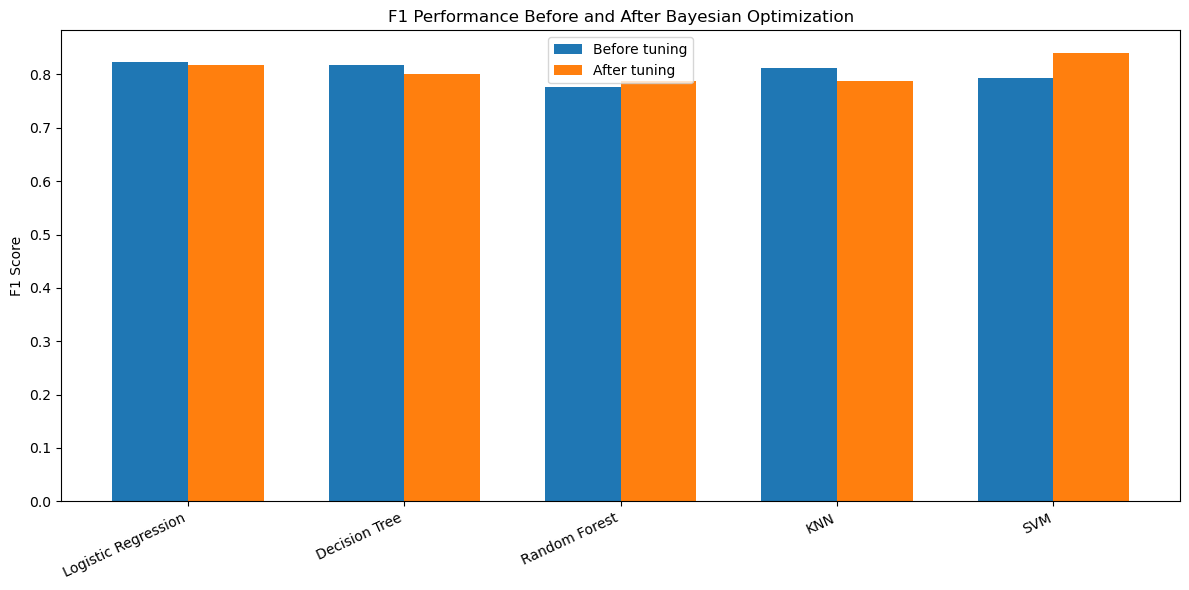

In [24]:
model_names = comparison_df["Model"]
x = np.arange(len(model_names))
width = 0.35

plt.figure(figsize=(12, 6))

plt.bar(
    x - width / 2,
    comparison_df["Baseline_F1"],
    width,
    label="Before tuning"
)

plt.bar(
    x + width / 2,
    comparison_df["Tuned_F1"],
    width,
    label="After tuning"
)

plt.xticks(x, model_names, rotation=25, ha="right")
plt.ylabel("F1 Score")
plt.title("F1 Performance Before and After Bayesian Optimization")
plt.legend()
plt.tight_layout()
plt.show()

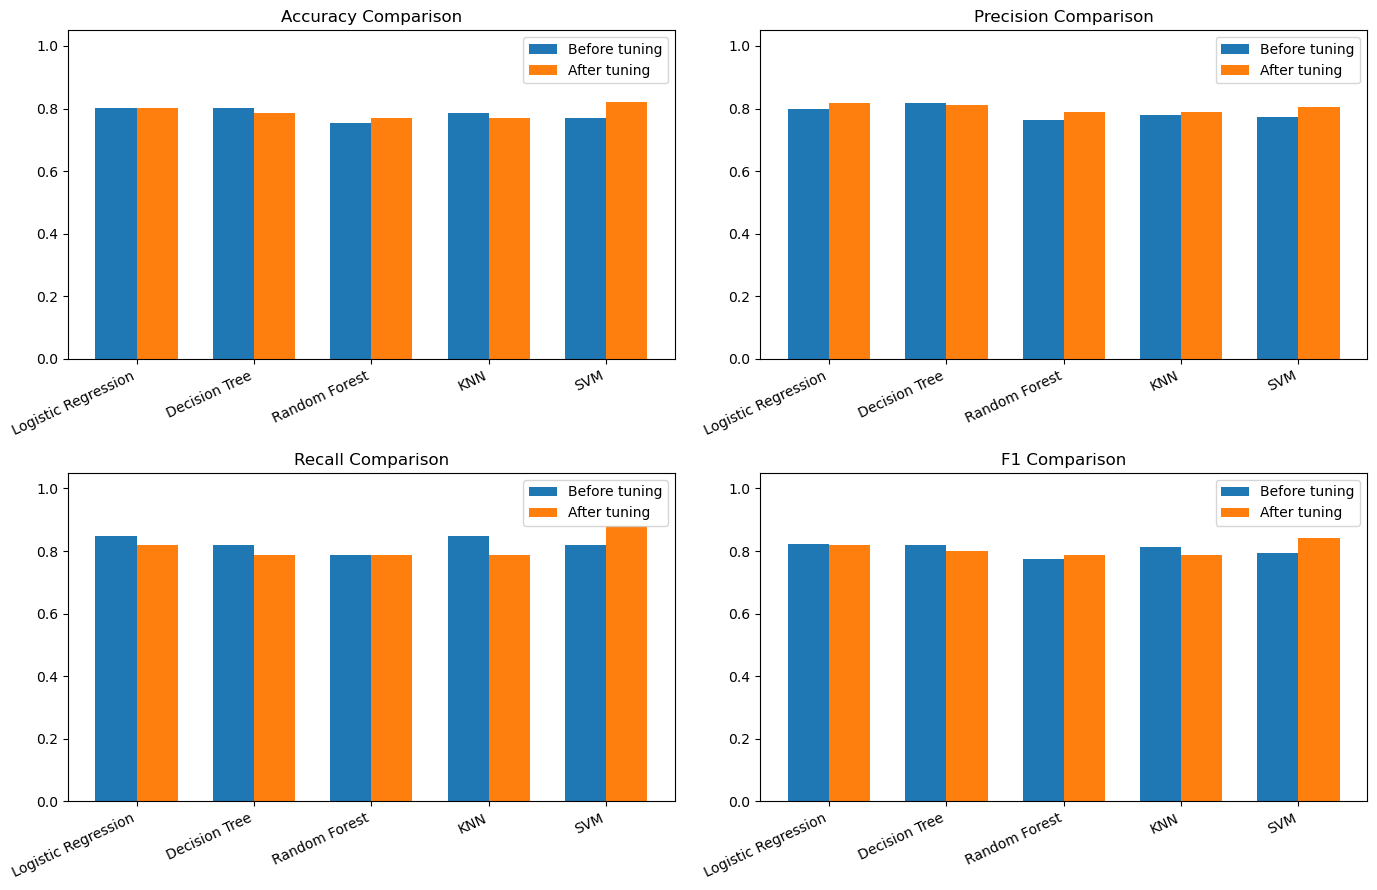

In [25]:
metrics = ["Accuracy", "Precision", "Recall", "F1"]

fig, axes = plt.subplots(2, 2, figsize=(14, 9))

for ax, metric in zip(axes.flatten(), metrics):

    ax.bar(
        x - width / 2,
        comparison_df["Baseline_" + metric],
        width,
        label="Before tuning"
    )

    ax.bar(
        x + width / 2,
        comparison_df["Tuned_" + metric],
        width,
        label="After tuning"
    )

    ax.set_title(metric + " Comparison")
    ax.set_xticks(x)
    ax.set_xticklabels(model_names, rotation=25, ha="right")
    ax.set_ylim(0, 1.05)
    ax.legend()

plt.tight_layout()
plt.show()



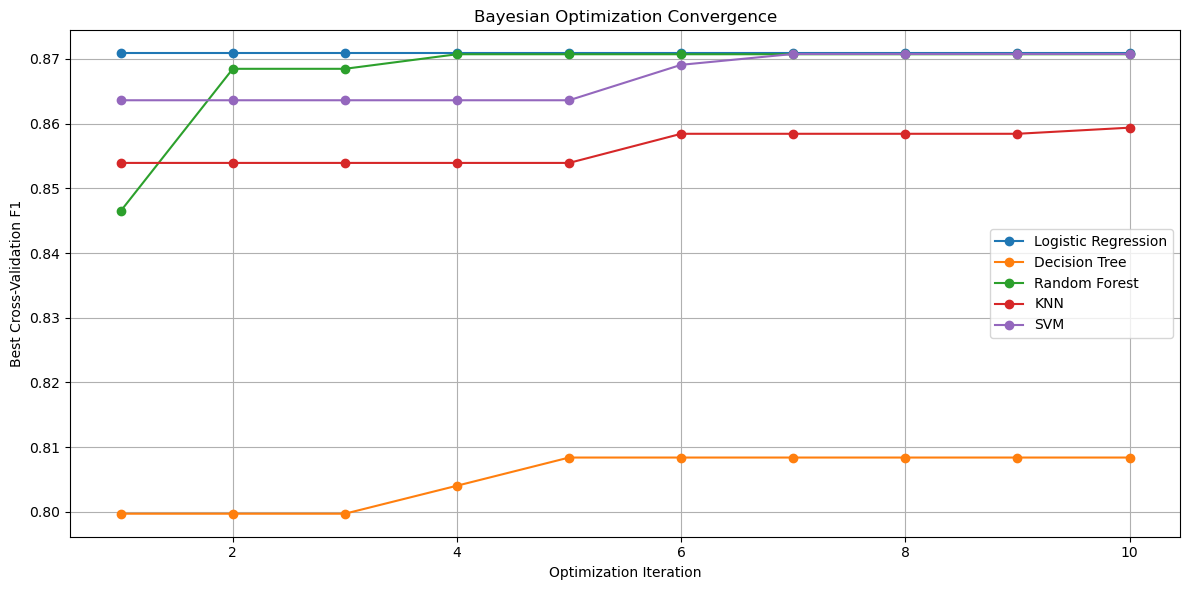

In [26]:
plt.figure(figsize=(12, 6))

for model_name in models.keys():

    model_history = convergence_df[
        convergence_df["Model"] == model_name
    ]

    plt.plot(
        model_history["Iteration"],
        model_history["Best_CV_F1"],
        marker="o",
        label=model_name
    )

plt.xlabel("Optimization Iteration")
plt.ylabel("Best Cross-Validation F1")
plt.title("Bayesian Optimization Convergence")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

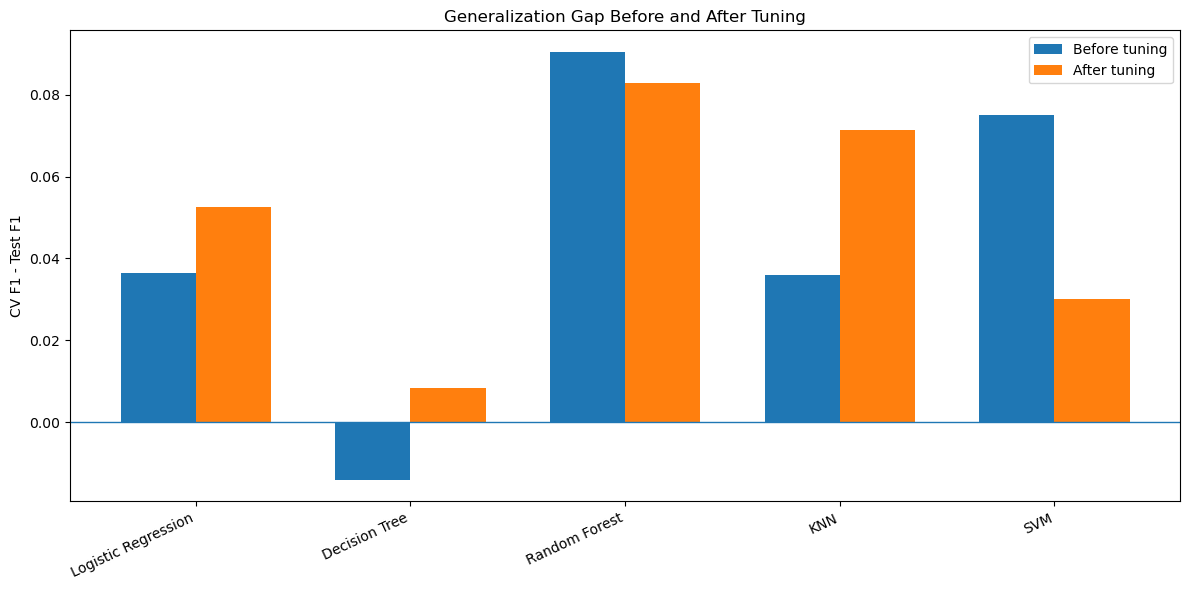

In [27]:
plt.figure(figsize=(12, 6))

plt.bar(
    x - width / 2,
    comparison_df["Baseline_Generalization_Gap"],
    width,
    label="Before tuning"
)

plt.bar(
    x + width / 2,
    comparison_df["Tuned_Generalization_Gap"],
    width,
    label="After tuning"
)

plt.axhline(0, linewidth=1)

plt.xticks(x, model_names, rotation=25, ha="right")
plt.ylabel("CV F1 - Test F1")
plt.title("Generalization Gap Before and After Tuning")
plt.legend()
plt.tight_layout()
plt.show()

In [28]:
print("\nPERFORMANCE ANALYSIS")

for _, row in comparison_df.iterrows():

    print("\nModel:", row["Model"])

    print(
        "F1 before:",
        round(row["Baseline_F1"], 4)
    )

    print(
        "F1 after:",
        round(row["Tuned_F1"], 4)
    )

    print(
        "F1 improvement:",
        round(row["F1_Improvement"], 4)
    )

    print(
        "Percentage improvement:",
        round(row["F1_Improvement_Percent"], 2),
        "%"
    )

    if row["F1_Improvement"] > 0:
        print("Result: Performance improved.")
    elif row["F1_Improvement"] < 0:
        print("Result: Performance decreased.")
    else:
        print("Result: No change in F1.")


PERFORMANCE ANALYSIS

Model: Logistic Regression
F1 before: 0.8235
F1 after: 0.8182
F1 improvement: -0.0053
Percentage improvement: -0.65 %
Result: Performance decreased.

Model: Decision Tree
F1 before: 0.8182
F1 after: 0.8
F1 improvement: -0.0182
Percentage improvement: -2.22 %
Result: Performance decreased.

Model: Random Forest
F1 before: 0.7761
F1 after: 0.7879
F1 improvement: 0.0118
Percentage improvement: 1.52 %
Result: Performance improved.

Model: KNN
F1 before: 0.8116
F1 after: 0.7879
F1 improvement: -0.0237
Percentage improvement: -2.92 %
Result: Performance decreased.

Model: SVM
F1 before: 0.7941
F1 after: 0.8406
F1 improvement: 0.0465
Percentage improvement: 5.85 %
Result: Performance improved.


In [29]:
print("\nBEST MODEL BEFORE TUNING:", best_before_name)
print("BEST MODEL AFTER TUNING:", best_after_name)

print("\nBEST BAYESIAN PARAMETERS:")
print(best_after_params)

print("\nBEST CROSS-VALIDATION F1:")
print(round(best_after_score, 4))


BEST MODEL BEFORE TUNING: Logistic Regression
BEST MODEL AFTER TUNING: Logistic Regression

BEST BAYESIAN PARAMETERS:
{'model__C': 10, 'model__solver': 'liblinear', 'model__class_weight': 'balanced'}

BEST CROSS-VALIDATION F1:
0.8709


In [30]:
import hashlib
from datetime import datetime, timezone

MODEL_VERSION = "1.3.0"

safe_name = best_after_name.lower().replace(" ", "_")

export_dir = os.path.join(
    "model_exports",
    safe_name,
    "v" + MODEL_VERSION
)

os.makedirs(export_dir, exist_ok=True)

model_path = os.path.join(
    export_dir,
    safe_name + "_v" + MODEL_VERSION + ".joblib"
)

import joblib

joblib.dump(
    best_after_model,
    model_path,
    compress=("gzip", 3),
    protocol=5
)

def calculate_sha256(path):
    digest = hashlib.sha256()

    with open(path, "rb") as file:
        for chunk in iter(lambda: file.read(8192), b""):
            digest.update(chunk)

    return digest.hexdigest()

metadata = {
    "model_name": best_after_name,
    "version": MODEL_VERSION,
    "best_parameters": best_after_params,
    "best_cv_f1": float(best_after_score),
    "created_at_utc": datetime.now(timezone.utc).isoformat(),
    "model_file": os.path.basename(model_path),
    "sha256": calculate_sha256(model_path)
}

with open(
    os.path.join(export_dir, "manifest.json"),
    "w",
    encoding="utf-8"
) as file:
    json.dump(metadata, file, indent=4)

print("\nALL COMPARISONS COMPLETED")
print("Comparison CSV: before_after_tuning_comparison.csv")
print("Convergence CSV: bayesian_convergence_results.csv")
print("Best tuned model:", os.path.abspath(model_path))



ALL COMPARISONS COMPLETED
Comparison CSV: before_after_tuning_comparison.csv
Convergence CSV: bayesian_convergence_results.csv
Best tuned model: /home/patel-krish/anaconda3/BrainyBeam/Heart_Diesease/model_exports/logistic_regression/v1.3.0/logistic_regression_v1.3.0.joblib
